## Visualizzazioni V0

Input: /home/alessio-grisorio/TESI/hj_reachability/results/brt/euclidean.npz
Campo: V0; v_E=6, v_H=6, delta_E=0 rad


/tmp/ipykernel_667947/2242050099.py:134: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig_v0.subplots_adjust(
/home/alessio-grisorio/TESI/hj_reachability/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


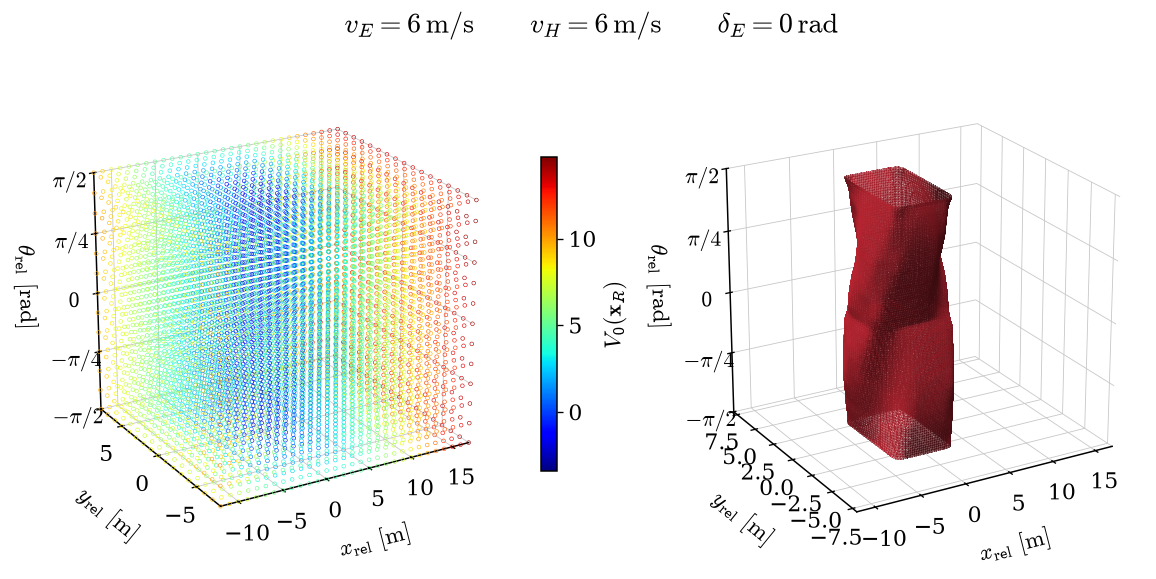

In [1]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from plot_utils import set_style, export_figure

set_style()


# Individua la radice del repository.
ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "scripts" / "plot_terminal_value.py").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Apri il notebook all'interno del repository hj_reachability."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts import plot_terminal_value as terminal
from scripts import compare_terminal_values as comparison


# ---------------- Configurazione ----------------

METRIC = "euclidean"
DATA_DIRECTORY = ROOT / "results" / "brt"

V_E = 6.0
V_H = 6.0
DELTA_E = 0.0

X_LIMITS = None
Y_LIMITS = None
THETA_LIMITS = (-np.pi / 2, np.pi / 2)

FIGURE_SIZE = (12.0, 5.0)
ELEVATION = 22
AZIMUTH = -120

COLORMAP = "jet"
COLOR_LIMITS = None
SCATTER_STRIDE = (1, 1, 2)
SCATTER_SIZE = 5.0

SURFACE_COLOR = plt.get_cmap("RdBu_r")(0.88)
SURFACE_ALPHA = 0.5
SURFACE_REFINEMENT = 4
SMOOTHING_SIGMA = 0.8

# ------------------------------------------------


terminal.KEY = "V0"
terminal.DATA_DIRECTORY = DATA_DIRECTORY
terminal.INPUT_FILE = None

terminal.V_E = V_E
terminal.V_H = V_H
terminal.DELTA_E = DELTA_E

terminal.X_LIMITS = X_LIMITS
terminal.Y_LIMITS = Y_LIMITS
terminal.THETA_LIMITS = THETA_LIMITS
terminal.ELEVATION = ELEVATION
terminal.AZIMUTH = AZIMUTH

comparison.V_E_3D = V_E
comparison.V_H = V_H
comparison.DELTA_E = DELTA_E
comparison.SURFACE_ALPHA = SURFACE_ALPHA
comparison.SURFACE_REFINEMENT = SURFACE_REFINEMENT
comparison.SMOOTHING_SIGMA = SMOOTHING_SIGMA


# Carica V0 e interpola nelle coordinate fissate.
axes, values, field_label = terminal.load_slice(METRIC)
extended_axes, extended_values, limits = terminal.prepare_domain(
    axes, values
)

interpolator = terminal.RegularGridInterpolator(
    extended_axes,
    extended_values,
    bounds_error=True,
)

scatter_axes = [
    axis[
        (axis >= lower - 1e-7)
        & (axis <= upper + 1e-7)
    ][::stride]
    for axis, (lower, upper), stride in zip(
        axes, limits, SCATTER_STRIDE
    )
]

if any(len(axis) == 0 for axis in scatter_axes):
    raise ValueError("Nessun nodo scatter nei limiti selezionati.")

points = np.stack(
    np.meshgrid(*scatter_axes, indexing="ij"),
    axis=-1,
).reshape(-1, 3)

point_values = interpolator(points)

vmin, vmax = (
    COLOR_LIMITS
    if COLOR_LIMITS is not None
    else (float(values.min()), float(values.max()))
)

if not vmin < vmax:
    raise ValueError("Seleziona limiti colore con minimo < massimo.")

norm = colors.Normalize(vmin=vmin, vmax=vmax)
cmap = plt.get_cmap(COLORMAP)


# Figura nello stile del grafico 3D originale.
fig_v0 = plt.figure(figsize=FIGURE_SIZE)

fig_v0.subplots_adjust(
    left=0.03,
    right=0.96,
    bottom=0.12,
    top=0.88,
    wspace=0.55,
)

ax_scatter = fig_v0.add_subplot(121, projection="3d")
ax_surface = fig_v0.add_subplot(122, projection="3d")

for ax in (ax_scatter, ax_surface):
    terminal.configure_axis(ax, limits)
    ax.tick_params(labelsize=plt.rcParams["xtick.labelsize"])

ax_scatter.scatter(
    *points.T,
    s=SCATTER_SIZE,
    facecolors="none",
    edgecolors=cmap(norm(point_values)),
    linewidths=0.35,
    depthshade=False,
    rasterized=True,
)

colorbar = fig_v0.colorbar(
    cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax_scatter,
    shrink=0.68,
    pad=0.08,
    fraction=0.035,
)

colorbar.set_label(rf"${field_label}$")
colorbar.ax.tick_params(labelsize=plt.rcParams["ytick.labelsize"])

# La routine dei confronti riceve una fetta già fissata:
# gli ultimi tre assi sono quindi singleton.
surface_axes = [
    *axes,
    np.array([V_H]),
    np.array([DELTA_E]),
    np.array([V_E]),
]

comparison.plot_surface(
    ax_surface,
    surface_axes,
    values[..., None, None, None],
    SURFACE_COLOR,
    METRIC,
    limits,
)
fig_v0.suptitle(
    rf"$v_E={V_E:g}\,\mathrm{{m/s}}"
    rf"\qquad v_H={V_H:g}\,\mathrm{{m/s}}"
    rf"\qquad \delta_E={DELTA_E:g}\,\mathrm{{rad}}$",
    y=1.0,
)
plt.show()

In [2]:
# Salvataggio
export_figure(
    fig_v0,
    nome="euclidean_v0",
    cartella=METRIC,
    formati=("pdf", "eps"),
    sovrascrivi=True,
)

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_v0.pdf


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as uni

Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_v0.eps


[PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_v0.pdf'),
 PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_v0.eps')]